# Step 4 - Tune the model  (1 - 7 Nov)
Settings are chosen **on the validation set only**, one shared configuration for the three versions. Then feature importance, and the final configuration is frozen before the test set is touched.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import pandas as pd
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)
from toadwatch import config as C
from toadwatch.modeling import feature_importance, train_all
from toadwatch.reporting import plot_feature_importance
from toadwatch.tuning import freeze_final_config, grid_search, load_final_config
tr = pd.read_parquet(C.INTERIM_DIR / 'features_train.parquet'); va = pd.read_parquet(C.INTERIM_DIR / 'features_val.parquet')
X_tr, y_tr, X_va, y_va = tr.drop(columns='label'), tr.label, va.drop(columns='label'), va.label

In [2]:
results = grid_search(X_tr, y_tr, X_va, y_va)   # ~2-3 minutes
results.head(10).round(4)

,n_estimators,max_depth,min_samples_leaf,max_features,call_only_f1,call_only_accuracy,message_only_f1,message_only_accuracy,combined_f1,combined_accuracy,mean_f1
0,200,NaN,1,0.3,0.9902,0.9902,0.9136,0.9146,0.9830,0.9829,0.9622
1,400,12.0,1,sqrt,0.9878,0.9878,0.9127,0.9146,0.9830,0.9829,0.9612
2,200,24.0,1,0.3,0.9902,0.9902,0.9086,0.9098,0.9830,0.9829,0.9606
3,400,12.0,1,0.3,0.9853,0.9854,0.9104,0.9122,0.9853,0.9854,0.9603
4,400,24.0,2,0.3,0.9878,0.9878,0.9059,0.9073,0.9854,0.9854,0.9597
5,400,NaN,2,0.3,0.9878,0.9878,0.9059,0.9073,0.9854,0.9854,0.9597
6,400,NaN,1,0.3,0.9878,0.9878,0.9064,0.9073,0.9829,0.9829,0.9590
7,200,24.0,1,sqrt,0.9878,0.9878,0.9037,0.9049,0.9854,0.9854,0.9589
8,400,12.0,2,0.3,0.9878,0.9878,0.9037,0.9049,0.9854,0.9854,0.9589
9,200,NaN,2,0.3,0.9830,0.9829,0.9082,0.9098,0.9854,0.9854,0.9588


In [3]:
# Frozen on 26 Oct, before the test set was opened; after the final test it can no longer change.
cfg = load_final_config() if C.FINAL_TEST_LOCK.exists() else freeze_final_config(results)
cfg

{'params': {'n_estimators': 200,
  'max_depth': None,
  'min_samples_leaf': 1,
  'max_features': 0.3},
 'selected_by': 'mean validation F1 over the three versions',
 'mean_val_f1': 0.9622482317248789,
 'seed': 42}

## Which features matter most?

channel
call       0.828064
message    0.171936
Name: importance, dtype: float64

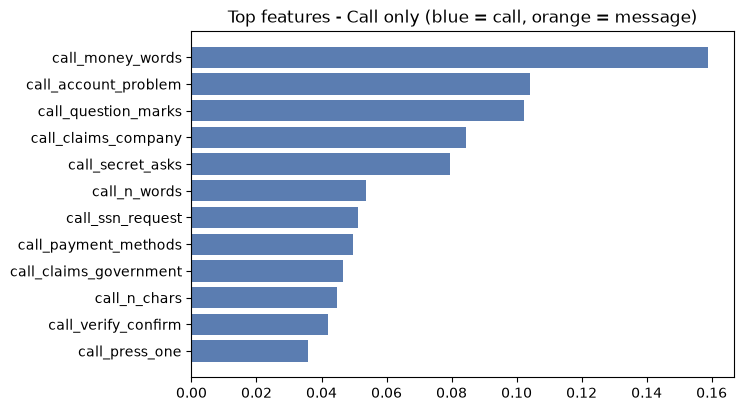

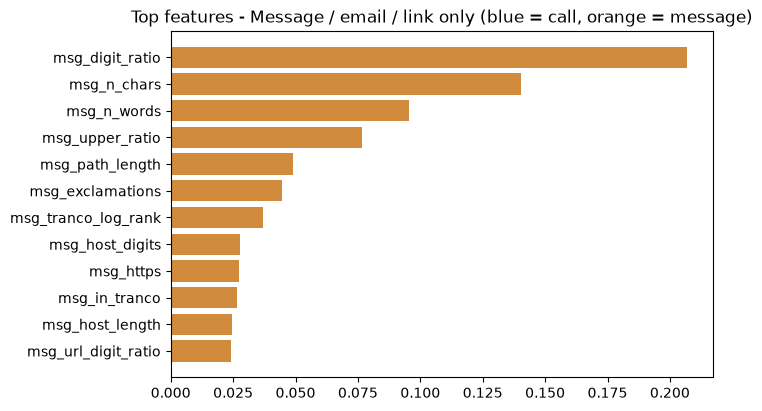

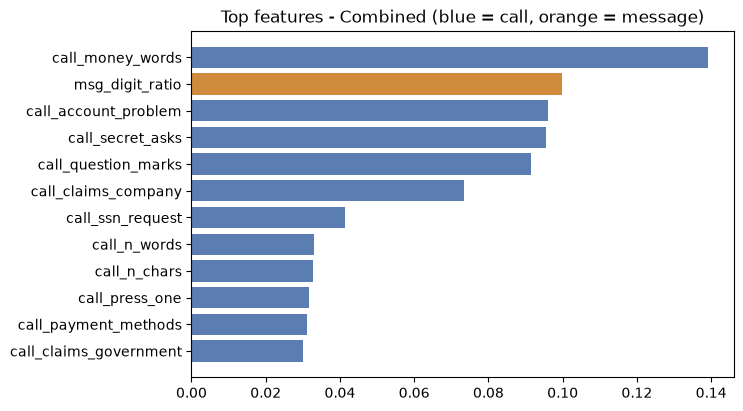

In [4]:
models = train_all(X_tr, y_tr, cfg['params'])
imp = feature_importance(models)
for v in ['call_only', 'message_only', 'combined']:
    plot_feature_importance(imp, v, name=f'step4_importance_{v}')
imp[imp.variant == 'combined'].groupby('channel').importance.sum()

Read this carefully in the report: `call_question_marks` and length features suggest part of the call signal is *dialogue style* (see `experiments/ablation_and_shortcuts.py`).